# Lab 1: Multi-Armed Bandits (10-armed testbed)

**Course:** Reinforcement Learning, Semester 6, Plaksha University

Learning objectives:
1. Understand the exploration-exploitation trade-off
2. Implement epsilon-greedy action selection
3. Compare sample-average and constant step-size updates
4. Analyse performance in stationary and nonstationary environments

The experiments follow Sutton and Barto, Chapter 2 (Figure 2.2 and Exercises 2.3 and 2.5).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from typing import List, Tuple
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility 
# change the value (1234) with last 4 digits of your student ID
np.random.seed(26)


The k-armed bandit problem:
- You face `k` slot machines (arms), each with `unknown reward distributions`

- At each time step, you `select one arm` and `receive a reward`

- Goal: `Maximize total reward` over time

Key challenge: `EXPLORATION vs EXPLOITATION`

- `Exploitation`: Choose the best known arm

- `Exploration`: Try other arms to find potentially better options


## Part 1: The bandit environment

In [2]:
class MultiArmedBandit:
    """
    A k-armed bandit environment for reinforcement learning experiments.

    Each arm has a true (unknown) value q*(a).
    Rewards are sampled from N(q*(a), 1).
    """

    def __init__(self, k: int = 10, stationary: bool = True,
                 mean: float = 0.0, std: float = 1.0, verbose=False):

        self.k = k
        self.stationary = stationary

        # Initialize true action values q*(a)
        self.q_true = np.random.normal(mean, std, size=k)

        # Optimal action (arm with highest true value)
        self.optimal_action = np.argmax(self.q_true)
        
        if verbose:
            print(f"\nInitialized {k}-armed bandit (stationary={stationary})")

    def pull(self, action: int) -> float:
        """
        Pull an arm and receive a reward.
        Reward ~ N(q*(action), 1)
        """

        # Sample reward
        reward = np.random.normal(self.q_true[action], 1.0)

        # If non-stationary, apply random walk to all q*
        if not self.stationary:
            self.q_true += np.random.normal(0, 0.01, size=self.k)
            self.optimal_action = np.argmax(self.q_true)

        return reward

    def get_optimal_action(self) -> int:
        """Return the current optimal action."""
        return self.optimal_action


## Part 2: Reward distributions of the 10 arms

In [3]:
def plot_arm_reward_distributions(bandit: MultiArmedBandit, 
                                  samples_per_arm: int = 200) -> None:
    """
    Samples rewards from each arm of the bandit and visualizes
    the reward distributions using a violin plot.
    """

    k = bandit.k

    # 1️⃣ Create reward storage matrix
    rewards = np.zeros((samples_per_arm, k))

    # 2️⃣ Collect rewards
    for a in range(k):
        for i in range(samples_per_arm):
            rewards[i, a] = bandit.pull(a)

    # 3️⃣ Empirical mean reward μ̂ for each arm
    empirical_means = rewards.mean(axis=0)

    # 4️⃣ True mean rewards q*(a)
    true_means = bandit.q_true

    # 5️⃣ Plot violin plots
    plt.figure(figsize=(12, 6))
    plt.violinplot(rewards, showmeans=False, showextrema=False)

    plt.scatter(
        range(1, k + 1),
        empirical_means,
        color='red',
        label='Empirical Mean (μ̂)'
    )

    plt.scatter(
        range(1, k + 1),
        true_means,
        color='black',
        marker='x',
        label='True Mean (q*)'
    )

    plt.xlabel("Arm")
    plt.ylabel("Reward")
    plt.title("Reward Distributions of Each Bandit Arm")
    plt.legend()
    plt.grid(True)
    plt.show()


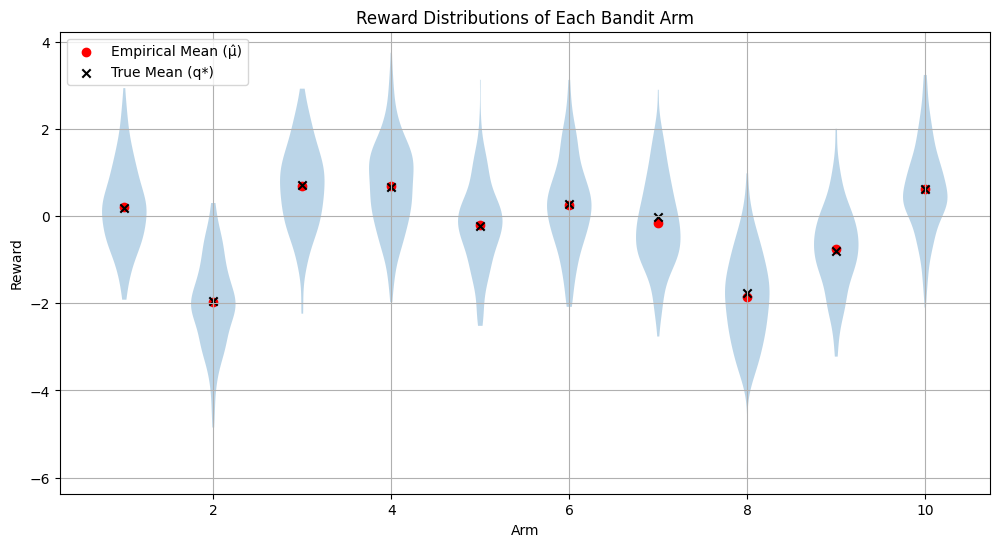

In [4]:
plot_arm_reward_distributions(MultiArmedBandit(k=10))

## Part 3: The agent (epsilon-greedy, sample-average or constant step size)

In [5]:
import numpy as np

class BanditAgent:
    """
    An agent that learns to select actions in a k-armed bandit problem.
    """
    
    def __init__(self, k: int, epsilon: float = 0.1, 
                 step_size: float = None, initial_value: float = 0.0, verbose=False):
        """
        Initialize the bandit agent.
        """
        self.k = k
        self.epsilon = epsilon
        self.step_size = step_size
        
        # Initialize action-value estimates Q(a)
        self.Q = np.ones(k) * initial_value
        
        # Initialize action counts N(a)
        self.N = np.zeros(k)
        
        if verbose:
            print(f"\nInitialized agent: ε={epsilon}, step_size={step_size}, Q_init={initial_value}")
    
    def select_action(self) -> int:
        """
        Select an action using ε-greedy policy.
        """
        # Exploration
        if np.random.rand() < self.epsilon:
            action = np.random.randint(self.k)
        
        # Exploitation
        else:
            max_value = np.max(self.Q)
            # Handle ties randomly
            candidates = np.where(self.Q == max_value)[0]
            action = np.random.choice(candidates)
        
        return action
    
    def update(self, action: int, reward: float):
        """
        Update action-value estimates after receiving a reward.
        """
        # Increment action count
        self.N[action] += 1
        
        # Determine step size α
        if self.step_size is None:
            alpha = 1.0 / self.N[action]  # sample-average
        else:
            alpha = self.step_size       # constant step size
        
        # Incremental update
        self.Q[action] += alpha * (reward - self.Q[action])
    
    def reset(self, initial_value: float = 0.0):
        """
        Reset the agent for a new run.
        """
        self.Q = np.ones(self.k) * initial_value
        self.N = np.zeros(self.k)


## Part 4: Exercise 2.3, weighting of past rewards

In [6]:
import numpy as np

print("\n" + "=" * 70)
print("PART 4: EXERCISE 2.3 - WEIGHTED AVERAGE ANALYSIS")
print("=" * 70)

print("""
EXERCISE 2.3: If the step-size parameters αₙ are not constant, then the 
estimate Qₙ is a weighted average of previously received rewards with a 
weighting different from that given by (2.6). What is the weighting on each 
prior reward for the general case, analogous to (2.6), in terms of the 
sequence of step-size parameters?

SOLUTION DERIVATION:
Starting from: Q_{n+1} = Q_n + α_n[R_n - Q_n]
             = (1 - α_n)Q_n + α_n R_n

Expanding recursively:
Q_{n+1} = α_n R_n + (1-α_n)Q_n
        = α_n R_n + (1-α_n)[α_{n-1} R_{n-1} + (1-α_{n-1})Q_{n-1}]
        = α_n R_n + (1-α_n)α_{n-1} R_{n-1} + (1-α_n)(1-α_{n-1})Q_{n-1}
        ...

GENERAL FORMULA:
Q_{n+1} = (∏ᵢ₌₁ⁿ (1-αᵢ))Q₁ + ∑ᵢ₌₁ⁿ [αᵢ ∏ⱼ₌ᵢ₊₁ⁿ (1-αⱼ)] Rᵢ

Weight on reward Rᵢ = αᵢ ∏ⱼ₌ᵢ₊₁ⁿ (1-αⱼ)

For constant α (special case):
Weight on Rᵢ = α(1-α)^(n-i)  [exponential decay!]

For sample-average (α_n = 1/n):
Weight on Rᵢ = 1/n  [uniform weighting]
""")

# INTERACTIVE DEMONSTRATION

print("\n" + "-" * 70)
print("INTERACTIVE DEMONSTRATION: Weight Comparison")
print("-" * 70)

n = 10
constant_alpha = 0.1

print(f"\nComparing weights for n={n} rewards:")
print(f"Constant α = {constant_alpha} vs Sample-average (α = 1/n)")
print("\nReward | Constant α | Sample-avg | Difference")
print("-" * 55)

for i in range(1, n + 1):
    # Constant step-size weight
    weight_constant = constant_alpha * (1 - constant_alpha) ** (n - i)
    
    # Sample-average weight
    weight_sample_avg = 1 / n
    
    # Difference
    difference = weight_constant - weight_sample_avg
    
    print(f"{i:^6} | {weight_constant:^11.6f} | {weight_sample_avg:^10.6f} | {difference:^10.6f}")

print("\nNOTE:")
print("- Older rewards have very small weight with constant α")
print("- Recent rewards dominate (recency bias)")
print("- Sample-average treats all rewards equally")



PART 4: EXERCISE 2.3 - WEIGHTED AVERAGE ANALYSIS

EXERCISE 2.3: If the step-size parameters αₙ are not constant, then the 
estimate Qₙ is a weighted average of previously received rewards with a 
weighting different from that given by (2.6). What is the weighting on each 
prior reward for the general case, analogous to (2.6), in terms of the 
sequence of step-size parameters?

SOLUTION DERIVATION:
Starting from: Q_{n+1} = Q_n + α_n[R_n - Q_n]
             = (1 - α_n)Q_n + α_n R_n

Expanding recursively:
Q_{n+1} = α_n R_n + (1-α_n)Q_n
        = α_n R_n + (1-α_n)[α_{n-1} R_{n-1} + (1-α_{n-1})Q_{n-1}]
        = α_n R_n + (1-α_n)α_{n-1} R_{n-1} + (1-α_n)(1-α_{n-1})Q_{n-1}
        ...

GENERAL FORMULA:
Q_{n+1} = (∏ᵢ₌₁ⁿ (1-αᵢ))Q₁ + ∑ᵢ₌₁ⁿ [αᵢ ∏ⱼ₌ᵢ₊₁ⁿ (1-αⱼ)] Rᵢ

Weight on reward Rᵢ = αᵢ ∏ⱼ₌ᵢ₊₁ⁿ (1-αⱼ)

For constant α (special case):
Weight on Rᵢ = α(1-α)^(n-i)  [exponential decay!]

For sample-average (α_n = 1/n):
Weight on Rᵢ = 1/n  [uniform weighting]


------------------------------------

## Part 5: Running experiments

In [7]:
def run_experiment(bandit: MultiArmedBandit, 
                   agent: BanditAgent, 
                   steps: int) -> Tuple[np.ndarray, np.ndarray]:
    """
    Run a single experiment: agent interacting with bandit.
    
    Returns:
    --------
    rewards : np.ndarray
        Reward at each time step
    optimal_actions : np.ndarray
        1 if optimal action selected, 0 otherwise
    """
    
    rewards = np.zeros(steps)
    optimal_actions = np.zeros(steps)
    
    for t in range(steps):
        # 1. Agent selects an action
        action = agent.select_action()
        
        # 2. Pull the arm and get reward
        reward = bandit.pull(action)
        
        # 3. Update the agent's estimates
        agent.update(action, reward)
        
        # 4. Record reward
        rewards[t] = reward
        
        # 5. Record whether optimal action was chosen
        if action == bandit.get_optimal_action():
            optimal_actions[t] = 1
    
    return rewards, optimal_actions


In [8]:
def run_multiple_experiments(k: int = 10, 
                             stationary: bool = True,
                             epsilon: float = 0.1,
                             step_size: float = None,
                             steps: int = 10000,
                             runs: int = 2000) -> Tuple[np.ndarray, np.ndarray]:
    """
    Run multiple independent experiments and average results.
    
    Returns:
    --------
    avg_rewards : np.ndarray
        Average reward at each time step
    avg_optimal : np.ndarray
        Average % of optimal action at each time step
    """
    
    all_rewards = np.zeros((runs, steps))
    all_optimal = np.zeros((runs, steps))
    
    print(f"\nRunning {runs} experiments with {steps} steps each...")
    print(f"Settings: stationary={stationary}, ε={epsilon}, α={step_size}")
    
    for run in range(runs):
        if (run + 1) % 500 == 0:
            print(f"  Completed {run + 1}/{runs} runs...")
        
        # Create a new bandit for each run
        bandit = MultiArmedBandit(k=k, stationary=stationary)
        
        # Create a new agent for each run
        agent = BanditAgent(k=k, epsilon=epsilon, step_size=step_size)
        
        # Run one full experiment
        rewards, optimal = run_experiment(bandit, agent, steps)
        
        # Store results
        all_rewards[run] = rewards
        all_optimal[run] = optimal
    
    # Average across all runs
    avg_rewards = np.mean(all_rewards, axis=0)
    
    # Convert optimal action counts to percentage
    avg_optimal = np.mean(all_optimal, axis=0) * 100
    
    return avg_rewards, avg_optimal


## Part 6: Reproducing Figure 2.2 (epsilon = 0, 0.01, 0.1)


Running ε = 0

Running 2000 experiments with 1000 steps each...
Settings: stationary=True, ε=0, α=None


  Completed 500/2000 runs...


  Completed 1000/2000 runs...


  Completed 1500/2000 runs...


  Completed 2000/2000 runs...

Running ε = 0.01

Running 2000 experiments with 1000 steps each...
Settings: stationary=True, ε=0.01, α=None


  Completed 500/2000 runs...


... (4 outputs left out)

  Completed 500/2000 runs...


  Completed 1000/2000 runs...


  Completed 1500/2000 runs...


  Completed 2000/2000 runs...


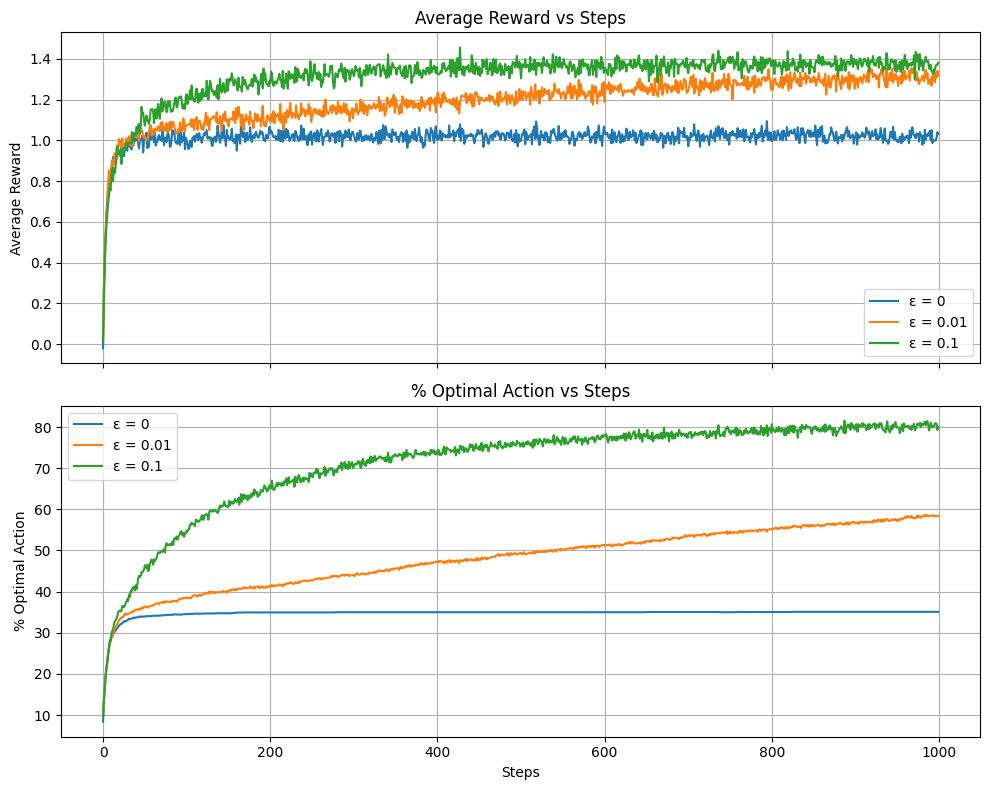

In [9]:
import matplotlib.pyplot as plt
import numpy as np

def run_epsilon_greedy_comparison(steps: int = 1000, runs: int = 2000) -> None:
    """
    Replicates Sutton & Barto Figure 2.2:
    - Average reward vs steps
    - % Optimal action vs steps
    for ε ∈ {0, 0.01, 0.1} using the 10-armed stationary bandit testbed.

    Parameters:
    -----------
    steps : int
        Number of time steps per run 
    runs : int
        Number of independent bandit runs
    """

    # TODO 1: Define epsilon values to compare
    epsilons = [0, 0.01, 0.1]

    # TODO 2: Create dictionaries to store results
    avg_rewards = {}
    avg_optimal = {}

    # TODO 3: Run experiments for each epsilon
    for eps in epsilons:
        print(f"\nRunning ε = {eps}")
        rewards, optimal = run_multiple_experiments(
            k=10,
            stationary=True,
            epsilon=eps,
            step_size=None,   # sample-average
            steps=steps,
            runs=runs
        )
        avg_rewards[eps] = rewards
        avg_optimal[eps] = optimal

    # TODO 4: Plot results
    fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

    # ---- Plot 1: Average Reward vs Steps ----
    for eps in epsilons:
        axes[0].plot(avg_rewards[eps], label=f"ε = {eps}")
    axes[0].set_ylabel("Average Reward")
    axes[0].set_title("Average Reward vs Steps")
    axes[0].legend()
    axes[0].grid(True)

    # ---- Plot 2: % Optimal Action vs Steps ----
    for eps in epsilons:
        axes[1].plot(avg_optimal[eps], label=f"ε = {eps}")
    axes[1].set_xlabel("Steps")
    axes[1].set_ylabel("% Optimal Action")
    axes[1].set_title("% Optimal Action vs Steps")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

run_epsilon_greedy_comparison(steps=1000, runs=2000)    


### Answer the following questions:


1. Which ε performs best in the long run in terms of

   * cumulative reward
       ε = 0.1 performs best

            From the Average Reward vs Steps plot (top):

            ε = 0.1 converges to the highest average reward

            ε = 0.01 is second

            ε = 0 last
            Reason: ε = 0.1 keeps exploring, so it continues to find and exploit the true optimal arm 
            
   * probability of selecting the optimal action?
   
            ε = 0.1 performs best

            From the % Optimal Action vs Steps plot (bottom):

            ε = 0.1 reaches ~80% optimal action

            ε = 0.01 reaches ~58–60%

            ε = 0 plateaus early at ~35–36%

2. Compare and contrast the different rewards for ε, express your answer quantitatively using approximate values from the figure.

    
        Average Reward (≈ at 1000 steps)

        ε = 0: ~1.02

        ε = 0.01: ~1.32

        ε = 0.1: ~1.40

        ε = 0.1 achieves the highest long-term reward, while ε = 0 performs the worst due to no exploration.
        
        Optimal Action (≈ at 1000 steps)

        ε = 0: ~35%

        ε = 0.01: ~58–60%

        ε = 0.1: ~80%

        ε = 0.1 selects the optimal action most frequently in the long run.

## Part 7: EXERCISE 2.5: Design and conduct an experiment to demonstrate the difficulties that sample-average methods have for nonstationary problems.

Compare:
1. Sample-average method (α = 1/n) 
2. Constant step-size method (α = 0.1)

In both STATIONARY and NONSTATIONARY environments.


As in the exercise, each run lasts 10,000 steps. In the nonstationary bandit every q*(a) takes an independent random walk (step standard deviation 0.01) after each pull.

In [10]:
# TODO: run experiments and compare results

# TODO: Experiment 1: Stationary environment, sample-average
# stat_sample_rewards, stat_sample_optimal = run_multiple_experiments(

# TODO: Experiment 2: Stationary environment, constant step-size
# stat_constant_rewards, stat_constant_optimal = run_multiple_experiments(

# TODO: Experiment 3: Nonstationary environment, sample-average
# nonstat_sample_rewards, nonstat_sample_optimal = run_multiple_experiments(

# TODO: Experiment 4: Nonstationary environment, constant step-size
# nonstat_constant_rewards, nonstat_constant_optimal = run_multiple_experiments(


steps = 10000   # 10,000 steps as in the exercise; drift only matters over long runs
runs = 300      # fewer runs than Figure 2.2 to keep the run time reasonable
k = 10
epsilon = 0.1

# Experiment 1
stat_sample_rewards, stat_sample_optimal = run_multiple_experiments(
    k=k,
    stationary=True,
    epsilon=epsilon,
    step_size=None,     # α = 1/n
    steps=steps,
    runs=runs
)

# Experiment 2
stat_constant_rewards, stat_constant_optimal = run_multiple_experiments(
    k=k,
    stationary=True,
    epsilon=epsilon,
    step_size=0.1,
    steps=steps,
    runs=runs
)

# Experiment 3
nonstat_sample_rewards, nonstat_sample_optimal = run_multiple_experiments(
    k=k,
    stationary=False,
    epsilon=epsilon,
    step_size=None,     # α = 1/n
    steps=steps,
    runs=runs
)

# Experiment 4
nonstat_constant_rewards, nonstat_constant_optimal = run_multiple_experiments(
    k=k,
    stationary=False,
    epsilon=epsilon,
    step_size=0.1,
    steps=steps,
    runs=runs
)

print("\n✓ All experiments completed!")



Running 300 experiments with 10000 steps each...
Settings: stationary=True, ε=0.1, α=None



Running 300 experiments with 10000 steps each...
Settings: stationary=True, ε=0.1, α=0.1



Running 300 experiments with 10000 steps each...
Settings: stationary=False, ε=0.1, α=None



Running 300 experiments with 10000 steps each...
Settings: stationary=False, ε=0.1, α=0.1



✓ All experiments completed!


## Part 8: Visualisation

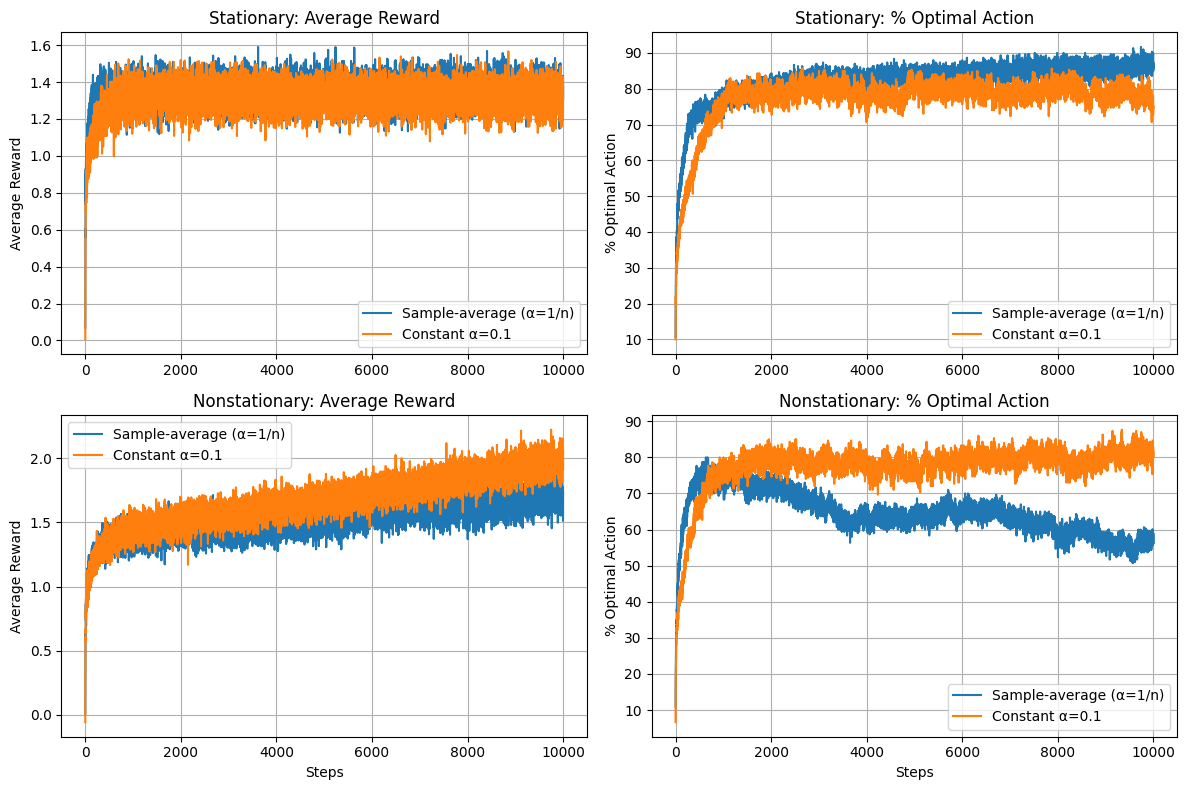

In [11]:
# TODO: Generate the 2×2 comparison plots for ALL 4 curves:
#   (1) Stationary: Average Reward
#   (2) Stationary: % Optimal Action
#   (3) Nonstationary: Average Reward
#   (4) Nonstationary: % Optimal Action

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

steps = np.arange(len(stat_sample_rewards))

# (1) Stationary: Average Reward
axes[0, 0].plot(steps, stat_sample_rewards, label="Sample-average (α=1/n)")
axes[0, 0].plot(steps, stat_constant_rewards, label="Constant α=0.1")
axes[0, 0].set_title("Stationary: Average Reward")
axes[0, 0].set_ylabel("Average Reward")
axes[0, 0].legend()
axes[0, 0].grid(True)

# (2) Stationary: % Optimal Action
axes[0, 1].plot(steps, stat_sample_optimal, label="Sample-average (α=1/n)")
axes[0, 1].plot(steps, stat_constant_optimal, label="Constant α=0.1")
axes[0, 1].set_title("Stationary: % Optimal Action")
axes[0, 1].set_ylabel("% Optimal Action")
axes[0, 1].legend()
axes[0, 1].grid(True)

# (3) Nonstationary: Average Reward
axes[1, 0].plot(steps, nonstat_sample_rewards, label="Sample-average (α=1/n)")
axes[1, 0].plot(steps, nonstat_constant_rewards, label="Constant α=0.1")
axes[1, 0].set_title("Nonstationary: Average Reward")
axes[1, 0].set_xlabel("Steps")
axes[1, 0].set_ylabel("Average Reward")
axes[1, 0].legend()
axes[1, 0].grid(True)

# (4) Nonstationary: % Optimal Action
axes[1, 1].plot(steps, nonstat_sample_optimal, label="Sample-average (α=1/n)")
axes[1, 1].plot(steps, nonstat_constant_optimal, label="Constant α=0.1")
axes[1, 1].set_title("Nonstationary: % Optimal Action")
axes[1, 1].set_xlabel("Steps")
axes[1, 1].set_ylabel("% Optimal Action")
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()


## Exercise 2.5: observations (values read from the plots at step 10,000)

| Environment | Sample average (alpha = 1/n) | Constant alpha = 0.1 |
|---|---|---|
| Stationary: % optimal action | about 87% | about 78% |
| Nonstationary: % optimal action | falls from about 75% (step 1,000) to about 57% | stays at about 80% |
| Nonstationary: average reward | about 1.65 | about 2.0 |

- **Stationary bandit:** sample averaging is slightly better. Its estimates converge to the true values, while a constant step size keeps reacting to recent noise.
- **Nonstationary bandit:** the true values drift (random walk, step standard deviation 0.01). With alpha = 1/n, every new reward counts less and less (weight 1/n, Exercise 2.3), so after a few thousand steps the estimates barely move and the agent keeps choosing an arm that is no longer the best. A constant alpha weights recent rewards exponentially more (weight alpha (1 - alpha)^(n - i)), so it keeps tracking the drifting values.
- This is exactly the difficulty the exercise asks for. It only shows up over long runs: at 1,000 steps (my first run) the values had not drifted far enough, and the two methods looked alike.